<a href="https://colab.research.google.com/github/TreesaAbraham/svd-image-compression-MATH344L/blob/main/notebook/01_image_as_matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("hello from colab")

hello from colab


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
A = data.camera()

#imports needed libraries and a pre-loaded grayscale image, which we save as A

In [ ]:
print("Shape:", A.shape) #512 x 512 matrix
print("Data type:", A.dtype) #uint8 = data type that stores whole numbers 0 to 255
print("Smallest entry:", A.min())
print("Largest entry:", A.max())
print("Top-left 3 x 3 block:\n", A[:3, :3]) #first three rows and columns

Shape: (512, 512)
Data type: uint8
Smallest entry: 0
Largest entry: 255
Top-left 3 x 3 block:
 [[200 200 200]
 [200 199 199]
 [199 199 199]]


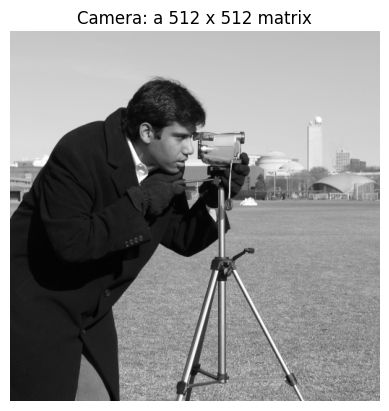

In [ ]:
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("Camera: a 512 x 512 matrix")
plt.axis("off")
plt.show()

#show the image in grayscale and give it a title

Color image shape: (512, 512, 3)


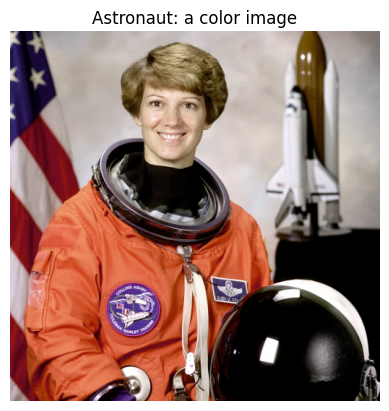

In [ ]:
C = data.astronaut()
print("Color image shape:", C.shape)
plt.imshow(C)
plt.title("Astronaut: a color image")
plt.axis("off")
plt.show()

#color image = has third dimension for RGB values, 512 x 512 x 3 matrix

In [ ]:
R = C[:, :, 0] # red channel
G = C[:, :, 1] # green channel
B = C[:, :, 2] # blue channel
print("Red channel shape:", R.shape)
print("Green channel shape:", G.shape)
print("Blue channel shape:", B.shape)

#treat the colors as three different matrices

Red channel shape: (512, 512)
Green channel shape: (512, 512)
Blue channel shape: (512, 512)


In [ ]:
x = np.array([200], dtype=np.uint8)
y = np.array([100], dtype=np.uint8)
print("uint8 200 + 100 =", x + y)
print("float 200 + 100 =", x.astype(float) + y.astype(float))

#need to convert to float as uint cannot hold numbers larger than 255

uint8 200 + 100 = [44]
float 200 + 100 = [300.]


In [ ]:
cross = np.array([
[0, 1, 1, 0],
[1, 1, 1, 1],
[1, 1, 1, 1],
[0, 1, 1, 0]
])
gradient = np.array([
[i + j for j in range(4)]
for i in range(4)
])
checker = np.array([
[(i + j + 1) % 2 for j in range(4)]
for i in range(4)
])

#creates 3 4x4 matrices, where 0 is black and 1 is white

In [ ]:
print("Cross rank =", np.linalg.matrix_rank(cross))
print("Gradient rank =", np.linalg.matrix_rank(gradient))
print("Checkerboard rank =", np.linalg.matrix_rank(checker))

#checkerboard only repeats two row patterns (rank = 2 = 2 pivot variables)

Cross rank = 2
Gradient rank = 2
Checkerboard rank = 2


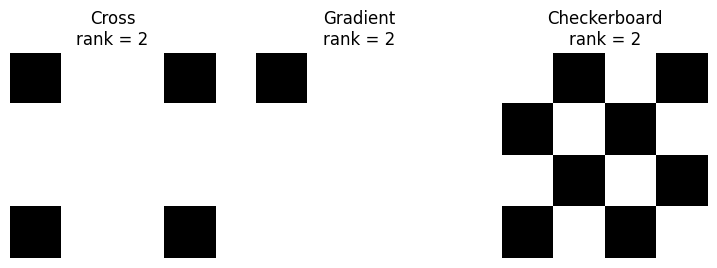

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
images = [("Cross", cross), ("Gradient", gradient),
("Checkerboard", checker)]

for ax, (name, M) in zip(axes, images):
  ax.imshow(M, cmap="gray", vmin=0, vmax=1)
  ax.set_title(f"{name}\nrank = {np.linalg.matrix_rank(M)}")
  ax.axis("off")
plt.show()

#create the images from the matrices in gray scale

[[1 1 1 1]
 [0 0 0 0]
 [1 1 1 1]
 [0 0 0 0]]
Rank = 1


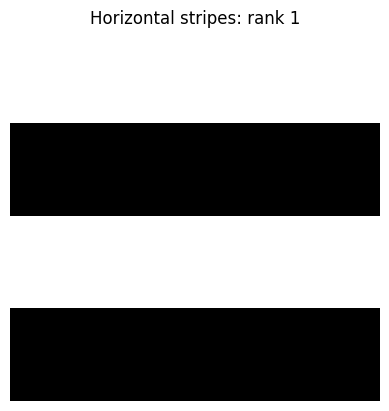

In [ ]:
u = np.array([1, 0, 1, 0])
v = np.array([1, 1, 1, 1])

stripes = np.outer(u, v)

print(stripes)
print("Rank =", np.linalg.matrix_rank(stripes))

plt.imshow(stripes, cmap="gray", vmin=0, vmax=1)
plt.title("Horizontal stripes: rank 1")
plt.axis("off")
plt.show()

#creates matrix with rank 1: less independent patterns (less data but also less detail)

In [ ]:
# cont. by part E

Arnav Mehta

In [ ]:
from google.colab import files
from PIL import Image

uploaded = files.upload()

#uses function to import in files from local drive and save it as uploaded

Saving 20260309_155426.jpg to 20260309_155426.jpg


In [ ]:
name = list(uploaded)[0]

img = Image.open(name). convert("L") #opens the chosen file and converts it to grayscale
img.thumbnail((800,800)) #sets size to make it viewable and small enough for Colab while maintaining proportions
P = np.array(img) #converts grayscale image into a numerical matrix (P), the dimensions of P are 450 x 800

print("Shape:", P.shape)
print("Data Type:", P.dtype)

Shape: (450, 800)
Data Type: uint8


(np.float64(-0.5), np.float64(799.5), np.float64(449.5), np.float64(-0.5))

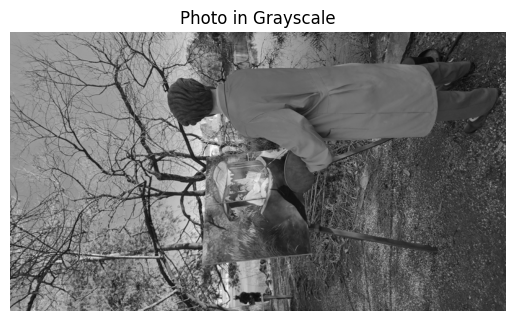

In [ ]:
plt.imshow(P, cmap = "gray", vmin = 0, vmax = 255)
plt.title("Sculpture in Grayscale")
plt.axis("off")

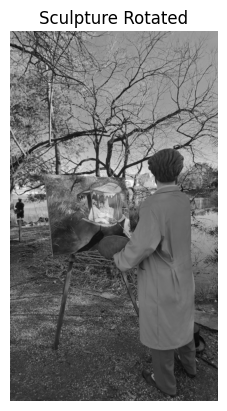

In [ ]:
P_rotated = np.rot90(P, k=-1) #rotate image 90 degrees clockwise (for proper orientation), #transpose the matrix

plt.imshow(P_rotated, cmap="gray", vmin=0, vmax=255)
plt.title("Sculpture Rotated")
plt.axis("off")
plt.show()

#same code to display the image

In [ ]:
print("Shape:", P_rotated.shape)

Shape: (800, 450)


Color Image Shape: (800, 450, 3)
Data Type: uint8


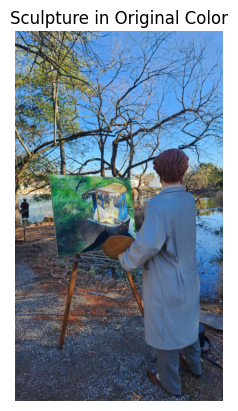

In [ ]:
#open the image in color rather than converting to grayscale (not for future SVD - just to test it out)
img_color = Image.open(name)
img_color.thumbnail((800, 800))

P_color = np.array(img_color) #convert to array

P_color_rotated = np.rot90(P_color, k=-1) #same code to rotate

print("Color Image Shape:", P_color_rotated.shape) #800 x 450 x 3, where 3 is RGB dimensions
print("Data Type:", P_color_rotated.dtype)

#show the image
plt.imshow(P_color_rotated)
plt.title("Sculpture in Original Color")
plt.axis("off")
plt.show()

Ali Wallam

Practice Exercises
1. 18 is basically black, 127 is grey, and 245 is a very light grey (almost white)
2. That would be 600 rows, 900 columns, and 3 color channels. This is a total of 1,620,000 numbers.
3. This selects the top left 5x5 block (rows 0-4 and columns 0-4).
4. With uint8, it wraps around because 270 is above the maximum. You get 14 because 270-256 = 14. Converting to float allows the correct sum of 270 to be calculated.
5. Predicted rank 2 because there are only 2 linearly independent/pivot rows. This was correct.
6. All rows are linear multiples of.a single pattern because np.outer creates a matrix where every row is a scalar multiple of v. Each row is the corresponding term of u multiplied by the vector v.

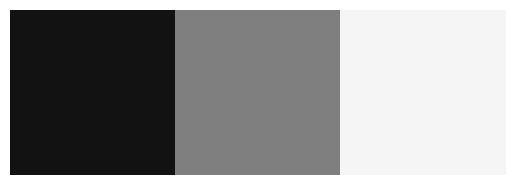

In [ ]:
#1
pixels = np.array([[18, 127, 245]])

plt.imshow(pixels, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()
#display grayscale pixels for the different values

In [ ]:
#2
600*900*3
#multiply rows x columns x color channels

1620000

In [ ]:
#3
print(A[:5, :5])
#colons select the rows and columns to print the top left 5x5 block

[[200 200 200 200 199]
 [200 199 199 200 199]
 [199 199 199 200 200]
 [200 200 199 199 199]
 [200 200 200 200 199]]


In [ ]:
#4
x = np.array([250], dtype=np.uint8)
y = np.array([20], dtype=np.uint8)

print("uint8 result:", x + y)
print("float result:", x.astype(float) + y.astype(float))
# adding two values as uint8 to show overflow and then as float

uint8 result: [14]
float result: [270.]


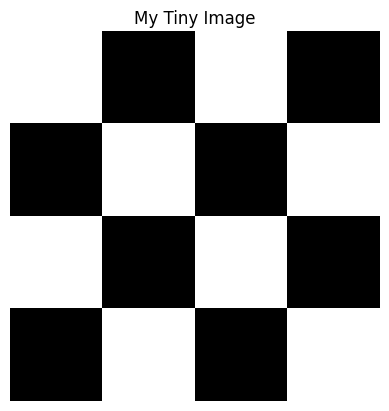

Rank = 2


In [ ]:
#5
M = np.array([
    [1, 0, 1, 0],
    [0, 1, 0, 1],
    [1, 0, 1, 0],
    [0, 1, 0, 1]
])

plt.imshow(M, cmap="gray", vmin=0, vmax=1)
plt.title("My Tiny Image")
plt.axis("off")
plt.show()

print("Rank =", np.linalg.matrix_rank(M))
#creating a 4x4 checkerboard and calculating its rank

[[ 1  0 -1  2]
 [ 2  0 -2  4]
 [ 3  0 -3  6]
 [ 4  0 -4  8]]
Rank = 1


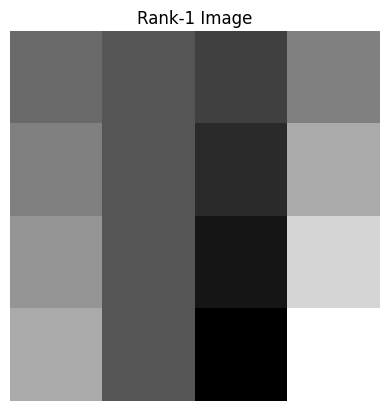

In [ ]:
#6
u = np.array([1, 2, 3, 4])
v = np.array([1, 0, -1, 2])

O = np.outer(u, v)

print(O)
print("Rank =", np.linalg.matrix_rank(O))

plt.imshow(O, cmap="gray", vmin=O.min(), vmax=O.max())
plt.title("Rank-1 Image")
plt.axis("off")
plt.show()
#Using outer product to create a rank 1 matrix where all rows are a multiple of the vector v